In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits

Load SCIENCE, BIAS and FLAT FITS files

In [2]:
dir = r"C:\Users\jw141\Desktop\astrolab_observations\\" #directory where fits files are found
file1 = r'C:\Users\jw141\Desktop\astrolab_observations\data\m27_new\m27_2025-09-15_20-47-21_black_0283.fits' #file names
science = fits.getdata(file1)  # data matrices
file2= dir+'master_bias.fits' #file names
master_bias = fits.getdata(file2)  # data matrices
file3= dir+'master_flat_black.fits' #file names
master_flat = fits.getdata(file3)  # data matrices

Calculate reduced SCIENCE data

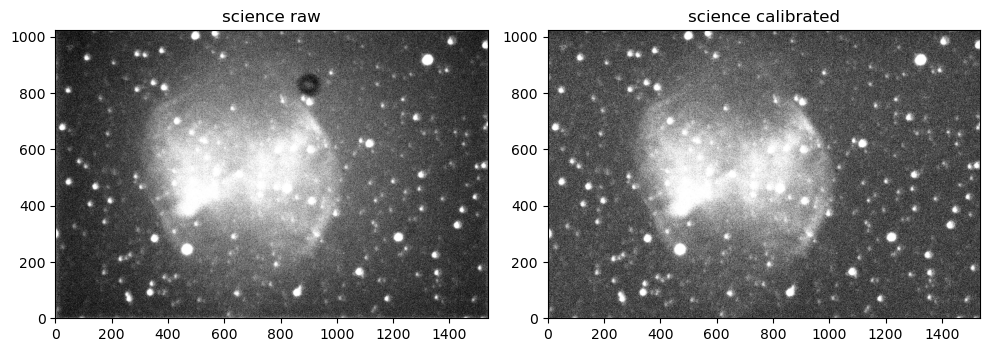

In [3]:
science_calibrated=(science-master_bias)/master_flat

#This example needs a mask! --------- WHY?
mask=np.zeros(np.shape(science_calibrated))
for i in range(len(science_calibrated)):
  for j in range(len(science_calibrated[i])):
    if master_flat[i][j]<0.2:
      science_calibrated[i][j]=0
      mask[i][j]=1
mask=mask.astype(bool)

fig, axs = plt.subplots(1,2, figsize=(10,6))
lo0,up0 = np.percentile(science,5),np.percentile(science,95)
axs[0].imshow(science,cmap='gray',clim=(lo0,up0),origin="lower")
axs[0].set_title("science raw")

lo,up = np.percentile(science_calibrated,5),np.percentile(science_calibrated,95)
axs[1].imshow(science_calibrated,cmap='gray',clim=(lo,up),origin="lower")#
axs[1].set_title("science calibrated")
plt.tight_layout()
plt.show()


**Backround**

In [4]:
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip

In [5]:
sigma_clip = SigmaClip(sigma=3.0) #object used to cut out outliers out of 3sigma interval
bkg_estimator = MedianBackground() #use the median as backround estimator, could also use the mean
bkg = Background2D(science_calibrated,(50,50),filter_size=(13,13),sigma_clip=sigma_clip, bkg_estimator=bkg_estimator,coverage_mask=mask)
#(50,50) image is divided in these boxes, backround is determined individiually in these boxes
#smaller boxes are locally more accurate but nosier, big boxes are smooth but less sensitive to small-scale-structures
#filter_size smooths the grid of backround boxes with (n,n) median filter to reduce noise
#coverage_mask optional boolean mask with same shape as image, pixels with mask=True are ignored in background calculation - dead pixels etc
print("      Median background found: %f, median bkg noise: %f" %(bkg.background_median,bkg.background_rms_median)  )

      Median background found: 363.395021, median bkg noise: 15.088435


**Plot data, background, and data-background**

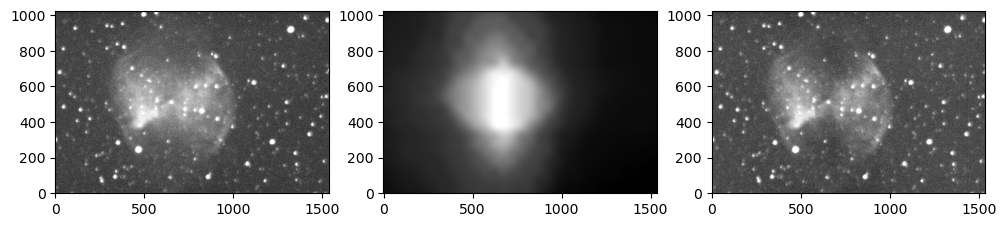

In [6]:
fig,ax = plt.subplots(1,3,figsize=(12,6))
lo,up = np.percentile(science_calibrated,1),np.percentile(science_calibrated,99)
ax[0].imshow(science_calibrated,cmap='gray',clim=(lo,up),origin="lower")
lo,up = np.percentile(bkg.background[mask==False],1),np.percentile(bkg.background[mask==False],99)
ax[1].imshow(bkg.background,cmap='gray',clim=(lo,up),origin="lower")
lo,up = np.percentile(science_calibrated-bkg.background,1),np.percentile(science_calibrated-bkg.background,99)
ax[2].imshow(science_calibrated-bkg.background,cmap='gray',clim=(lo,up),origin="lower")

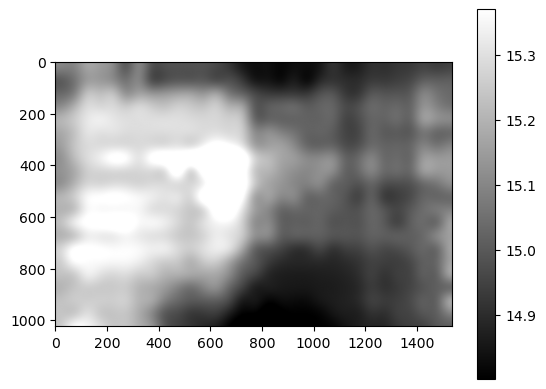

In [7]:
#variation of the backround
lo,up = np.percentile(bkg.background_rms[mask==False],1),np.percentile(bkg.background_rms[mask==False],95)
plt.imshow(bkg.background_rms,cmap='gray',clim=(lo,up))
plt.colorbar()